In [1]:
import numpy as np

In [9]:
class RegretMatching:
    def __init__(self, n_actions, indv_payoff_matrix):
        self.n_actions = n_actions
        self.cumulative_regret = np.zeros(n_actions)
        self.fixed_action_payoff = np.zeros(n_actions)
        self.mixed_strategy_payoff = 0
        self.cumulative_strategy = np.zeros(n_actions)
        self.sigma = np.full(1, n_actions) / n_actions
        self.indv_payoff = indv_payoff_matrix
        self.T = 0

    def each_round(self, opponent_move):
        self.cumulative_strategy += self.sigma
        self.T += 1
        payoff_t = np.dot(self.sigma, self.indv_payoff[opponent_move])
        self.mixed_strategy_payoff += payoff_t
        self.fixed_action_payoff += self.indv_payoff[opponent_move]
        self.cumulative_regret = self.fixed_action_payoff - self.mixed_strategy_payoff
        self.update_sigma()

    def update_sigma(self):
        tmp = self.flooring()
        if np.all(tmp == 0):
            self.sigma = np.full(1, self.n_actions) / self.n_actions
        else:
            self.sigma = tmp / tmp.sum()

    def make_decision(self):
        return np.random.choice(self.arange(self.n_actions), p=self.sigma)

    def flooring(self):
        return np.maximum(self.cumulative_regret, np.zeros(self.n_actions))

    def time_averaged_strategy(self):
        return self.cumulative_strategy / self.T

    def average_regret(self):
        return np.max(self.cumulative_regret) / self.T

    def cal_cce_violation(self, emp_joint_dist):
        avg_payoff = np.sum(self.indv_payoff * emp_joint_dist)
        fixed_actions_payoff = emp_joint_dist[None, :, :] * self.indv_payoff[:, None, :]
        fixed_actions_payoff = np.sum(fixed_actions_payoff, axis=(-1, -2))
        return np.max(fixed_actions_payoff - avg_payoff)

In [10]:
class RegretMatchingPlus(RegretMatching):
    def __init__(self, n_actions, indv_payoff_matrix):
        super()._init(n_actions, indv_payoff_matrix)

    def flooring(self):
        self.cumulative_regret = np.maximum(self.cumulative_regret, np.zeros(self.n_actions))
        return self.cumulative_regret

In [11]:
import numpy as np
x = np.array([[1, 2, 3],
              [4, 5, 6]])
b = np.array([[2, 5, 6],
              [1, 2, 3],
              [6, 7, 0]])

In [12]:
x[:, None, :]
# 2 x 3   3 x 3
# 3 x 2 x 3
print(x[None, :, :] * b[:, None, :])
np.sum(x[None, :, :] * b[:, None, :], axis=(-1, -2))

[[[ 2 10 18]
  [ 8 25 36]]

 [[ 1  4  9]
  [ 4 10 18]]

 [[ 6 14  0]
  [24 35  0]]]


array([99, 46, 79])

In [13]:
import argparse
import utils

class Experiment:
    def __init__(self, algo: str, payoff_matrix, game_name, T: int):
        payoff1 = payoff_matrix[:, :, 0]
        payoff2 = payoff_matrix[:, :, 1]
        n_actions1 = payoff1.shape[0]
        n_actions2 = payoff2.shape[1]
        if algo == "regret-matching":
            self.player1 = RegretMatching(n_actions1, payoff1)
            self.player2 = RegretMatching(n_actions2, payoff2)
        elif algo == "regret-matching-plus":
            self.player1 = RegretMatchingPlus(n_actions1, payoff1)
            self.player2 = RegretMatchingPlus(n_actions2, payoff2)
        else:
            pass

        self.T = T
        self.data = []
        self.emp_joint_dist = np.zeros((n_actions1, n_actions2))
        self.game_name = game_name

    def run_experiment(self):
        for t in range(self.T):
            data_t = {}
            a_t1 = self.player1.make_decision()
            a_t2 = self.player2.make_decision()
            self.update_emp_joint_dist(a_t1, a_t2)
            self.player1.each_round(a_t2)
            self.player2.each_round(a_t1)
            data_t["t"] = t
            data_t["average regret 1"] = self.player1.average_regret()
            data_t["average regret 2"] = self.player2.average_regret()
            data_t["time-averaged strategy 1"] = self.player1.time_averaged_strategy()
            data_t["time-averaged strategy 2"] = self.player2.time_averaged_strategy()

            cce_gap1 = self.player1.cal_cce_violation(self.emp_joint_dist)
            cce_gap2 = self.player2.cal_cce_violation(self.emp_joint_dist)
            data_t["cce_gap"] = max(cce_gap1, cce_gap2)

            self.data.append(data_t)

        pd.DataFrame(self.data).to_csv(f"data/{self.game_name}.csv", index=False)

    def update_emp_joint_dist(self, a_t1, a_t2):
        self.emp_joint_dist[a_t1, a_t2] += 1
        self.emp_joint_dist /= np.sum(self.emp_joint_dist)

def main():
    parser = argparse.ArgumentParser(prog="Running Regret Matching")
    parser.add_argument(
        '-g', '--game_name',
        type=str,
        choices = ['rps', 'asymmetric', 'shapley_game'],
        required = True,
        help='file name to the description of the game'
    )
    parser.add_argument(
        '--T',
        type=int,
        default=10000,
        help="Number of iterations"
    )
    parser.add_argument(
        '-a', '--algo',
        type=str,
        choices=['rm', 'rm+'],
    )

    algo = {
        'rm': "Regret Matching",
        'rm+': "Regret Matching +"
    }

    args = parser.parse_args()

    game_module = utils.load_game_info(args.game_name)
    print("="* 20, f"Running {algo[args.algo]} for game {game_module.GAME_NAME}\n \
          T = {args.T}\n")

    exp_runner = Experiment(algo=args.algo,
                            payoff_matrix=game_module.PAYOFFS,
                            game_name=args.game_name,
                            T = args.T)

    exp_runner.run_experiment()

In [14]:
import pandas as pd

In [15]:
x = [{1: 2, 2: 3},
     {1: 4, 2: 5}]
pd.DataFrame(x).to_csv("test.csv")

In [1]:
import nashpy as nash
import importlib
import numpy as np

In [4]:
rps = importlib.import_module("games.asymmetric")
payoff = rps.PAYOFFS
payoff_matrix = np.array(list(payoff.values())).reshape(3, 3, 2)[:, :, 0]
B = np.array(list(payoff.values())).reshape(3, 3, 2)[:, :, 1]
print(payoff_matrix)
print(B)
eqs = nash.Game(payoff_matrix, B).support_enumeration()
for eq in eqs:
    print(eq, "\n")

[[3 0 2]
 [1 2 1]
 [0 1 3]]
[[1 3 0]
 [2 1 2]
 [3 0 1]]
(array([0.33333333, 0.66666667, 0.        ]), array([0.5, 0.5, 0. ])) 



In [ ]:
np.sum([0.25      , 0.66666667, 0.08333333])

np.float64(1.0)

In [ ]:
3.33333333e-05

3.33333333e-05

In [ ]:
np.sum([3.35670354e-01, 6.64296313e-01, 3.33333333e-05])

np.float64(1.0000000003333)

In [ ]:
[3.35670354e-01 6.64296313e-01 3.33333333e-05],[5.04216388e-01 4.95700279e-01 8.33333333e-05]

SyntaxError: invalid syntax. Perhaps you forgot a comma? (52560521.py, line 1)

In [ ]:
payoff_matrix

array([[3, 0, 2],
       [1, 2, 1],
       [0, 1, 3]])

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import math
import json
import numpy as np

In [ ]:
df = pd.read_csv("data/rps_rm.csv")
df.head()

,t,average regret 1,average regret 2,time-averaged strategy 1,time-averaged strategy 2,cce_gap
0,0,1.000000,1.000000,[0.33333333 0.33333333 0.33333333],[0.33333333 0.33333333 0.33333333],2.00
1,1,0.500000,1.000000,[0.66666667 0.16666667 0.16666667],[0.16666667 0.16666667 0.66666667],1.00
2,2,0.333333,0.888889,[0.77777778 0.11111111 0.11111111],[0.11111111 0.33333333 0.55555556],1.00
3,3,0.500000,0.666667,[0.70833333 0.08333333 0.20833333],[0.08333333 0.5 0.41666667],1.50
4,4,0.400000,0.533333,[0.56666667 0.06666667 0.36666667],[0.06666667 0.6 0.33333333],0.75


In [ ]:
df_plus = pd.read_csv('data/rps_rmplus.csv')

In [ ]:

def read_nparray(df, df_plusseries: pd.Series) -> np.ndarray:
    series = series.apply(lambda x: np.array(x.strip('[]').split(), dtype=np.float64))
    return np.stack(series.to_list())

series = [read_nparray(df['time-averaged strategy 1']), read_nparray(df_plus['time-averaged strategy 2'])]

In [ ]:
class Player:
    def __init__(self, df: pd.DataFrame, df_plus: pd.DataFrame, i, indv_ne: tuple):
        self.df = self.reformat_df(df, i)
        self.df_plus = self.reformat_df(df_plus, i)
        self.indv_ne = indv_ne

    def read_nparray(self, df) -> np.ndarray:
        series = df['time-averaged strategy']
        series = series.apply(lambda x: np.array(x.strip('[]').split(), dtype=np.float64))
        return np.stack(series.to_list())
        
    def reformat_df(self, df, i):
        if i == 1 or i == 2:
            if i == 1:
                df = df.rename(columns={"time-averaged strategy 1": "time-averaged strategy",
                                    "average regret 1": "average regret"})
            else:
                df = df.rename(columns={"time-averaged strategy 2": "time-averaged strategy",
                                                    "average regret 2": "average regret"})
            nparray = self.read_nparray(df)
            for j in range(nparray.shape[1]):
                df.insert(len(df.columns), f"action {j + 1}", nparray[:, j])

            self.n_actions = nparray.shape[1]
            return df
 
        print('Only 2 players')
        return df
        

In [ ]:
players = [Player(df, df_plus, i, (1/3, 1/3, 1/3)) for i in range(1, 3)]

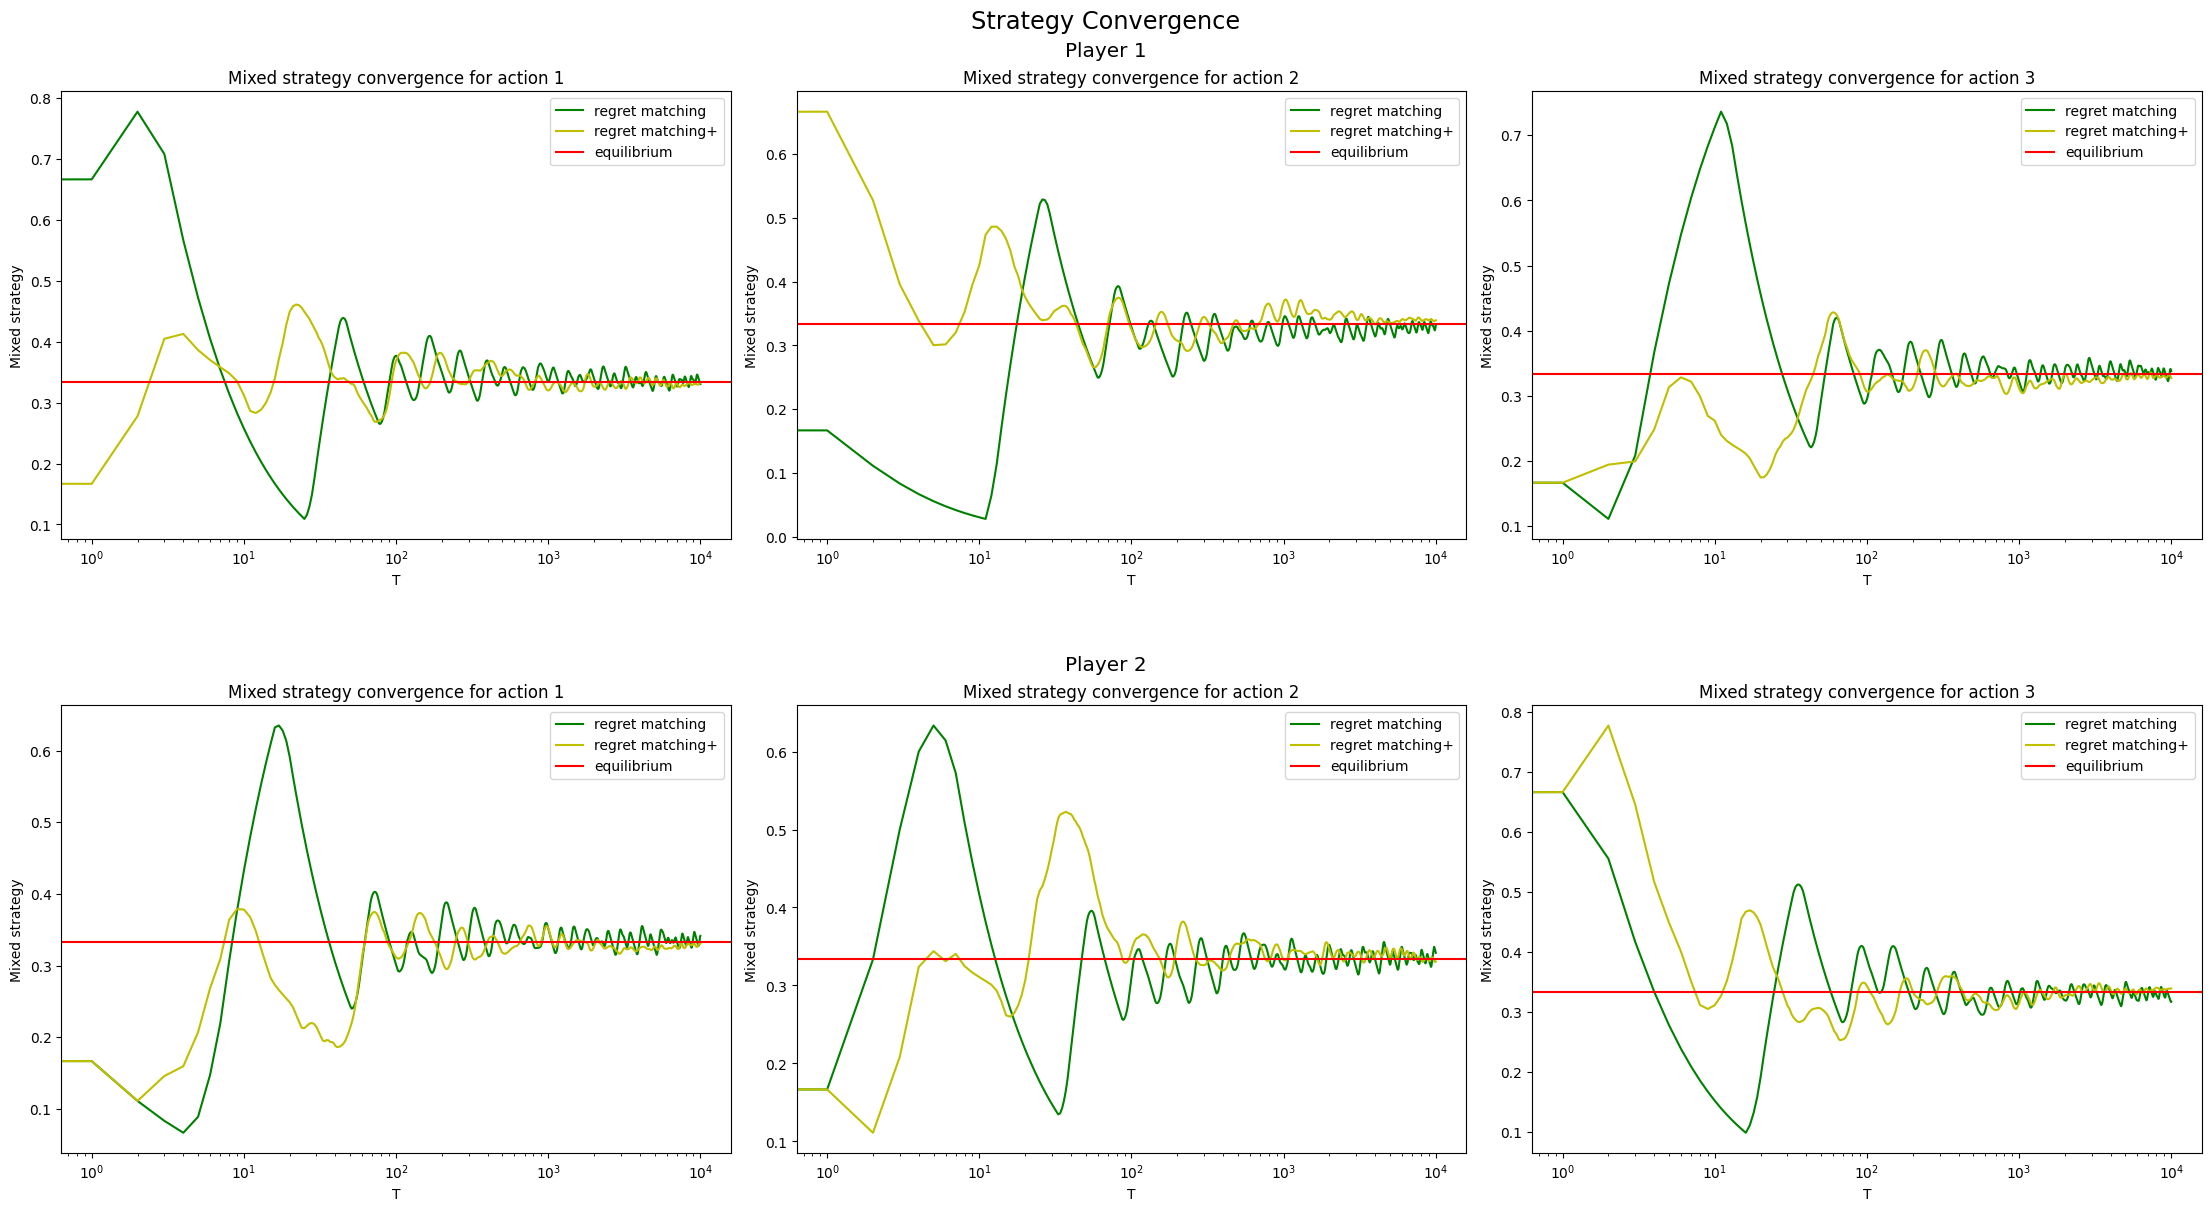

In [ ]:
n_actions = [p.n_actions for p in players]
fig = plt.figure(layout='constrained', figsize=(22, 12))
fig.suptitle("Strategy Convergence", fontsize='xx-large')
subfigs = fig.subfigures(nrows=len(players), ncols=1, hspace=0.1)

for i in range(len(players)):
    subfigs[i].suptitle(f"Player {i + 1}", fontsize='x-large')
    ax = subfigs[i].subplots(nrows=1, ncols=max(n_actions))
    for j in range(players[i].n_actions):
        ax[j].plot(players[i].df[f"action {j + 1}"], c='g', label="regret matching")
        ax[j].plot(players[i].df_plus[f"action {j + 1}"], c = 'y', label='regret matching+')
        ax[j].axhline(y=players[i].indv_ne[j], c='r', label='equilibrium')
        ax[j].set_xscale('log')
        ax[j].set_xlabel("T")
        ax[j].set_ylabel("Mixed strategy")
        ax[j].set_title(f"Mixed strategy convergence for action {j + 1}")
        ax[j].legend()

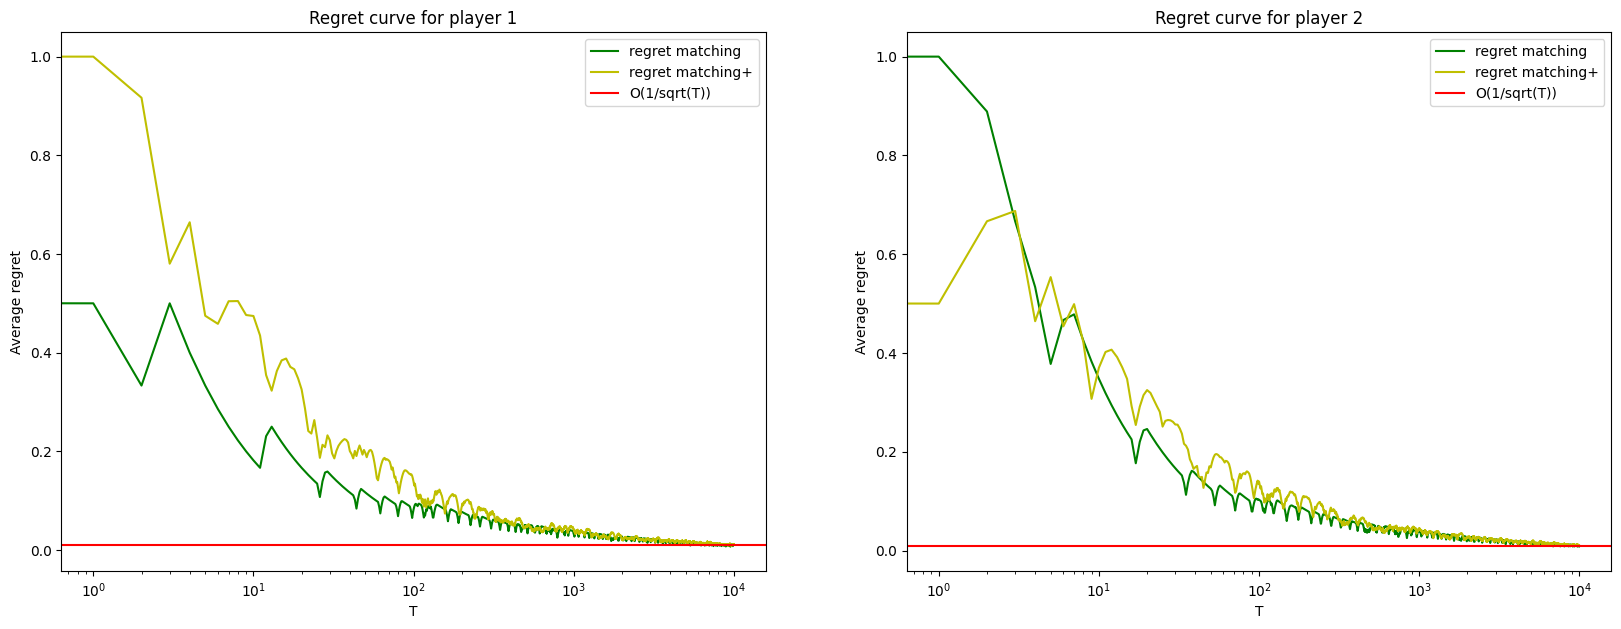

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=len(players), figsize=(20, 7))
for i in range(len(players)):
    ax[i].plot(players[i].df['average regret'], c='g', label="regret matching")
    ax[i].plot(players[i].df_plus['average regret'], c = 'y', label='regret matching+')
    ax[i].axhline(y=1/math.sqrt(10**4), c='r', label="O(1/sqrt(T))")
    ax[i].set_xscale('log')
    ax[i].set_xlabel("T")
    ax[i].set_ylabel("Average regret")
    ax[i].set_title(f"Regret curve for player {i + 1}")
    ax[i].legend()

In [ ]:
df.columns

Index(['t', 'average regret 1', 'average regret 2', 'time-averaged strategy 1',
       'time-averaged strategy 2', 'cce_gap'],
      dtype='str')

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=len(players), figsize=(20, 7))
for i in range(len(players)):
    ax[i].plot(players[i].df['average regret'], c='g', label="regret matching")
    ax[i].plot(players[i].df_plus['average regret'], c = 'y', label='regret matching+')
    ax[i].axhline(y=1/math.sqrt(10**4), c='r', label="O(1/sqrt(T))")
    ax[i].set_xscale('log')
    ax[i].set_xlabel("T")
    ax[i].set_ylabel("Average regret")
    ax[i].set_title(f"Regret curve for player {i + 1}")
    ax[i].legend()

In [ ]:
players = [Player(df, df_plus, i + 1, (1/3, 1/3, 1/3)) for i in range(2)]

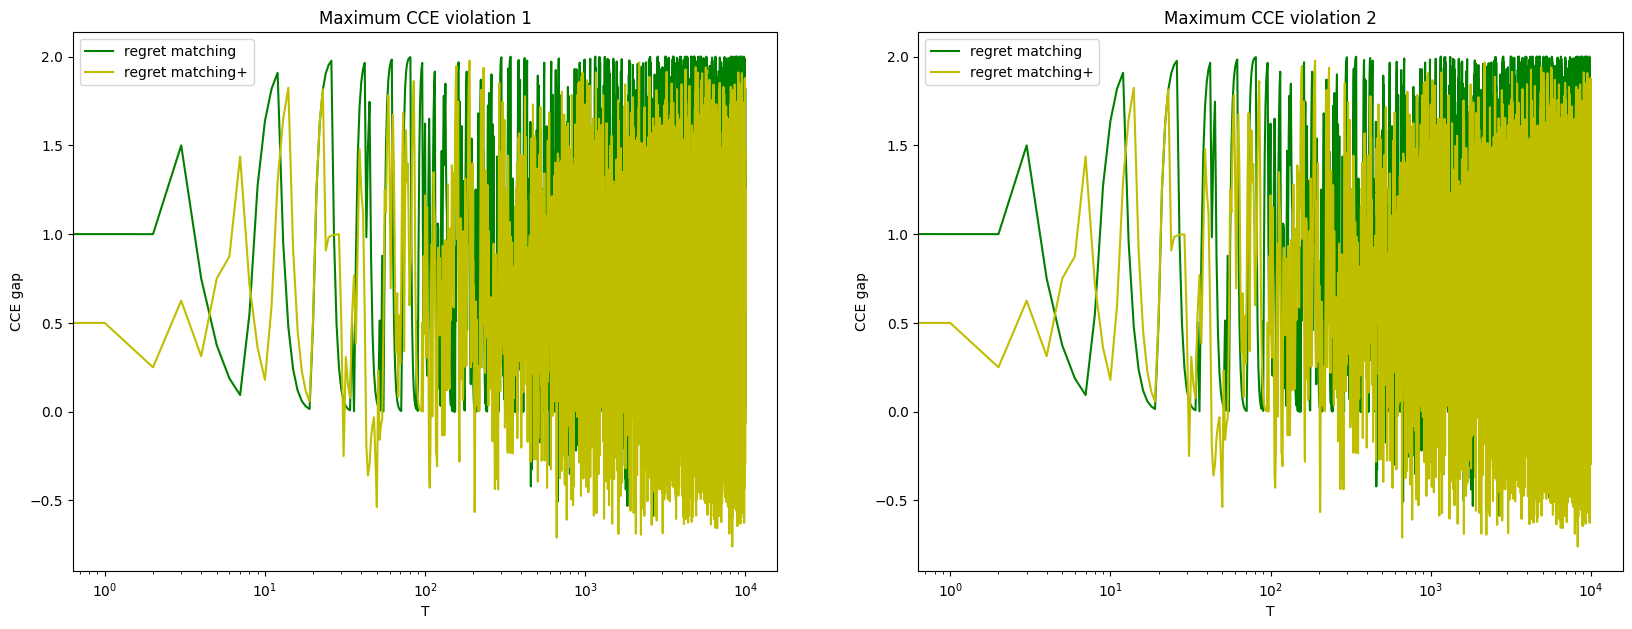

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=len(players), figsize=(20, 7))
for i in range(len(players)):
    ax[i].plot(players[i].df['cce_gap'], c='g', label="regret matching")
    ax[i].plot(players[i].df_plus['cce_gap'], c = 'y', label='regret matching+')
    ax[i].set_xscale('log')
    ax[i].set_xlabel("T")
    ax[i].set_ylabel("CCE gap")
    ax[i].set_title(f"Maximum CCE violation {i + 1}")
    ax[i].legend()

In [21]:
import json
import re
import getpass
import os
from openai import OpenAI, APIConnectionError, APIError, RateLimitError
from dotenv import load_dotenv
import time
import itertools
import sys
from pathlib import Path
import argparse

import utils
import config
import statistics
import pandas as pd
import math

In [29]:

class Analyst:
    """
    Script that produces the analysis plots and tables.
    file_name = "data/{game_name}/{game_name}.csv"
    """

    def __init__(self, file_name=None):
        self.filename = file_name

    def show_estimate_payoff(self, records: pd.DataFrame):
        # episodes_df = pd.DataFrame(records)
        episodes_df = records
        
        summary_rows = []
        for (s1, s2), group in episodes_df.groupby(["p1_strategy", "p2_strategy"], sort=False):
            u1_mean, u1_ci = self.mean_ci(group["u1"])
            u2_mean, u2_ci = self.mean_ci(group["u2"])
            summary_rows.append({
                "p1_strategy": s1, "p2_strategy": s2, "n": len(group),
                "u1_mean": u1_mean, "u1_ci95": u1_ci,
                "u2_mean": u2_mean, "u2_ci95": u2_ci,
            })
        
        estimates_df = pd.DataFrame(summary_rows)
        print(f"Emperical payoff estimation:\n{estimates_df}")
        if self.filename is not None:
            estimates_df.to_csv(self.filename)
        return estimates_df

    # 2.2 Compute the sample mean payoff
    # 2.3 Compute 95% confidence intervals
    def mean_ci(self, values):
        values = list(values)
        mean = statistics.fmean(values)
        half_width = 0.0 if len(values) < 2 else 1.96 * statistics.stdev(values) / math.sqrt(len(values))
        return mean, half_width


    def get_records(self, file_name):
        """
        json file
        """
        with open(file_name, 'r') as f:
            data = json.load(f)
        
        trials = data['trials']
        df_trials = pd.DataFrame(trials)

        return df_trials


# def main():
#     game_name = "rps"
#     game_module = utils.load_game_info(game_name)

#     print("=" * 20, f"Running {game_module.GAME_NAME}", "=" * 20)

#     experiment = ExperimentRunner(
#         game_module.PAYOFFS,
#         game_module.STRATEGY_PROMPTS,
#         game_name=game_name,
#         game_strategies=game_module.GAME_STRATEGIES,
#         game_actions=game_module.ACTIONS,
#         api_url=config.TAMU_BASE_URL,
#         model_name=config.SONNET_MODEL,
#         n_reps=config.N_REPS,
#     )

#     experiment.run_experiment()

#     stats = Analyst()
#     estimate_payoff_file = Path(f"data/{game_name}/{game_name}.csv")
#     estimate_payoff_file.parent.mkdir(parents=True, exist_ok=True)
#     records = stats.get_records(f"data/{game_name}/{game_name}.json")
#     stats.show_estimate_payoff(records)

# main()


In [46]:
stats = Analyst()
game_name = "rps"
estimate_payoff_file = Path(f"data/{game_name}/{game_name}.csv")
estimate_payoff_file.parent.mkdir(parents=True, exist_ok=True)
records = stats.get_records(f"data/{game_name}/{game_name}.json")
df = stats.show_estimate_payoff(records)

Emperical payoff estimation:
  p1_strategy p2_strategy  n  u1_mean  u1_ci95  u2_mean  u2_ci95
0     Uniform     Uniform  1     -1.0      0.0      1.0      0.0
1     Uniform     History  1      0.0      0.0      0.0      0.0
2     History     Uniform  1     -1.0      0.0      1.0      0.0
3     History     History  1      0.0      0.0      0.0      0.0


In [ ]:
for i in range(2):
    locs = df[f"u{i + 1}_mean"]
    scales = df[f"u{i + 1}_ci95"] / 1.96 / math.sqrt(T)
    df.insert(len(df.columns), f"u{i + 1}", np.random.normal(loc=locs, scale=scales))

In [48]:
df

,p1_strategy,p2_strategy,n,u1_mean,u1_ci95,u2_mean,u2_ci95,u1,u2
0,Uniform,Uniform,1,-1.0,0.0,1.0,0.0,-1.0,1.0
1,Uniform,History,1,0.0,0.0,0.0,0.0,0.0,0.0
2,History,Uniform,1,-1.0,0.0,1.0,0.0,-1.0,1.0
3,History,History,1,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
import pandas as pd

In [7]:
a = [{1: 'a', 2: 'b'},
     {1: 'n', 2: 'm'}]
pd.DataFrame(a)

,1,2
0,a,b
1,n,m


In [ ]:
from pathlib import Path
import utils
import config
import pandas as pd


from benchmark_experiments import Experiment
from llm_experiment_class import LLMExperiment
from analyst import Analyst
import plot_results
from player import Player

game_name = "rps"
game_module = utils.load_game_info(game_name)

print("=" * 20, f"Running {game_module.GAME_NAME}", "=" * 20)

experiment = LLMExperiment(
    game_module.PAYOFFS,
    game_module.STRATEGY_PROMPTS,
    game_name=game_name,
    game_strategies=game_module.GAME_STRATEGIES,
    game_actions=game_module.ACTIONS,
    api_url=config.TAMU_BASE_URL,
    model_name=config.SONNET_MODEL,
    n_reps=config.N_REPS,
)

experiment.run_experiment()

estimate_payoff_file = Path(f"data/{game_name}/{game_name}.csv")
estimate_payoff_file.parent.mkdir(parents=True, exist_ok=True)
stats = Analyst(file_name=estimate_payoff_file)
records = stats.get_records(f"data/{game_name}/{game_name}.json")
stats.show_estimate_payoff(records)

# Task 3.4
emp_payoff_matrix = utils.read_empirical_payoff_matrix(filename=f"data/{game_name}/{game_name}.csv",
                                                        strategies=game_module.GAME_STRATEGIES)
for algo in utils.ALGO:
    rm_experiment = Experiment(algo=algo,
                                payoffs=emp_payoff_matrix,
                                game_name=game_name,
                                T=5000)
    rm_experiment.run_experiment()


# Task 3.5
experiment.run_estimation_noise_experiment(
        n_resamples=10,
        random_seed=2026,
        T=5000,
)

df_plus = pd.read_csv(f"data/{game_name}_rmplus.csv")
NE = game_module.NE
players = [Player(None, df_plus, i + 1, NE[i]) for i in range(2)]
    
plot_results.plot_error_bands_strategy(players, game_name)
plot_results.regret_curve_noise(players, game_name)

In [ ]:
import logging
import config
import utils
from openai import OpenAI, APIConnectionError, APIError, RateLimitError
from dotenv import load_dotenv
import re
import getpass
import json
import itertools
import time
import pandas as pd
import numpy as np
from pathlib import Path
import os
from benchmark_experiments import Experiment


logging.getLogger("httpx").disabled = True

# Script that runs the LLM matchups and saves raw results.
class LLMExperiment:
    def __init__(self, payoffs_matrix, strategy_prompts, game_name = "", game_strategies = [], game_actions = [],
                 api_url: str = config.TAMU_BASE_URL,
                 model_name: str = config.SONNET_MODEL,
                 n_reps = config.N_REPS):

        self.game_name = game_name
        self.payoffs_matrix = payoffs_matrix
        self.strategy_prompts = strategy_prompts
        self.game_strategies = game_strategies
        self.game_actions_pattern = rf"\b({'|'.join(game_actions)})\b"
        self.api_url = api_url
        self.model = model_name
        self.n_reps = n_reps

        self.client = self.make_client()
        self.logger = utils.create_info_logger(f"{game_name}.log")
        logging.getLogger("httpx").setLevel(logging.WARNING)
        logging.getLogger("httpcore").setLevel(logging.WARNING)
        logging.getLogger("requests").setLevel(logging.WARNING)

    def make_client(self):
        load_dotenv()
        key = os.environ.get("TAMU_API_KEY") or getpass.getpass("TAMU_API_KEY: ")
        raw = os.environ.get("CF_COOKIE") or getpass.getpass("CF_COOKIE: ")
        return OpenAI(api_key=key,
                    base_url=self.api_url,
                    default_headers={"Cookie": utils.normalize_cf_cookie(raw)})


    # 2.1 Parse each LLM's response to extract its chosen action
    def _visible_content(self, response):
        """Read TAMU raw text/SSE replies or an OpenAI-compatible completion.
        Return the response and model used
        """
        model = None
        if isinstance(response, str):
            if "Cloudflare Access" in response and "Sign in" in response:
                raise RuntimeError(
                    "TAMU gateway returned the Cloudflare sign-in page; refresh CF_Authorization."
                )
            if response.lstrip().startswith("data:"):
                pieces = []
                for line in response.splitlines():
                    if not line.startswith("data:"):
                        continue
                    payload = line[5:].strip()
                    if not payload or payload == "[DONE]":
                        continue
                    try:
                        event = json.loads(payload)
                    except json.JSONDecodeError:
                        continue
                    if not model:
                        model = event["model"]
                    for choice in event.get("choices", []):
                        piece = choice.get("delta", {}).get("content")
                        if isinstance(piece, str):
                            pieces.append(piece)
                if pieces:
                    return re.sub(r"<think>.*?</think>", "", "".join(pieces), flags=re.DOTALL).strip(), model
            return response
        if isinstance(response, dict):
            choices = response.get("choices", [])
            if choices:
                message = choices[0].get("message", {})
                return message.get("content", "")
        try:
            return response.choices[0].message.content
        except (AttributeError, IndexError, KeyError, TypeError) as exc:
            raise TypeError(f"Unsupported TAMU completion response: {type(response).__name__}") from exc


    def _response_usage(self, response):
        if isinstance(response, str):
            if response.lstrip().startswith("data:"):
                for line in response.splitlines():
                    if not line.startswith("data:"):
                        continue
                    payload = line[5:].strip()
                    if not payload or payload == "[DONE]":
                        continue
                    try:
                        event = json.loads(payload)
                    except json.JSONDecodeError:
                        continue
                    usage = event.get("usage")
                    if usage is not None:
                        return usage
            else:
                try:
                    response = json.loads(response)
                except json.JSONDecodeError:
                    return None
        if isinstance(response, dict):
            return response.get("usage")
        return getattr(response, "usage", None)


    def choose_action(self, strategy, player_label):
        messages = [
            {"role": "system", "content": self.strategy_prompts[strategy]},
            {"role": "user", "content": f" This is the payoffs matrix {self.payoffs_matrix}. You are {player_label}. Choose your action now."},
        ]
        for attempt in range(4):
            try:
                api_response = self.client.chat.completions.create(
                    model=self.model,
                    messages=messages,
                    temperature=1.0,
                    max_tokens=16_384,
                )
                response, model = self._visible_content(api_response)
                visible = re.sub(
                    r"<think>.*?</think>", "", response,
                    flags=re.DOTALL,
                ).strip()
                actions = re.findall(self.game_actions_pattern, visible.upper())
                if not actions:
                    # Could not parse model's response
                    action = None
                else:
                    action = actions[-1]
                usage = self._response_usage(api_response)
                if isinstance(usage, dict):
                    prompt_tokens = usage.get("prompt_tokens", 0) or 0
                    completion_tokens = usage.get("completion_tokens", 0) or 0
                else:
                    prompt_tokens = getattr(usage, "prompt_tokens", 0) or 0
                    completion_tokens = getattr(usage, "completion_tokens", 0) or 0
                return action, visible, (
                    prompt_tokens,
                    completion_tokens,
                    ), model
            
            except (RateLimitError, APIConnectionError, APIError, ValueError) as exc:
                if attempt == 3:
                    raise
                delay = 2 ** attempt
                print(f"Transient {type(exc).__name__}; retrying in {delay}s...")
                time.sleep(delay)


    def run_experiment(self):
        self.logger.info(f"N_REPS = {self.n_reps}")
        n_api_call = self.n_reps * len(self.strategy_prompts)**2 * 2
        self.logger.info(f"Total of #API calls: {n_api_call}")
        records = []
        prompt_tokens = completion_tokens = 0
        parse_failure_count = 0

        for p1_strategy, p2_strategy in itertools.product(self.strategy_prompts, repeat=2):
            for rep in range(1, self.n_reps + 1):
                time.sleep(1)
                a1, text1, usage1, model_version = self.choose_action(p1_strategy, "Player 1")
                time.sleep(1)
                a2, text2, usage2, model_version = self.choose_action(p2_strategy, "Player 2")
                if not a1 or not a2:
                    parse_failure_count += 1
                    continue

                u1, u2 = self.payoffs_matrix[(a1, a2)]
                prompt_tokens += usage1[0] + usage2[0]
                completion_tokens += usage1[1] + usage2[1]
                record = {
                    "p1_strategy": p1_strategy,
                    "p2_strategy": p2_strategy,
                    "rep": rep,
                    "p1_action": a1,
                    "p2_action": a2,
                    "p1_raw_response": text1,
                    "p2_raw_response": text2,
                    "u1": u1,
                    "u2": u2,
                    "model_version": model_version
                }
                records.append(record)
                # if raw_example is None:
                #     raw_example = {**record, "p1_visible_response": text1, "p2_visible_response": text2}
            print(f"[{p1_strategy}, {p2_strategy}]: {self.n_reps}/{self.n_reps} complete")

        output = self.format_saved_output(records)
        self.logger.info(f"Returned model: {model_version}")
        self.logger.info(f"Parse failure count {parse_failure_count}/{n_api_call}")
        cost = round(prompt_tokens / 1e9 * 3 + completion_tokens / 1e9 * 15, 5)
        self.logger.info(f"Token cost total: ${cost}")
        self.save_to_json(output)

        return records


    def format_saved_output(self, records):
        payoffs = {f"{k[0], k[1]}": list(v) for k, v in self.payoffs_matrix.items()}
        output = {
            "game": {
                "name": self.game_name,
                "actions": self.game_strategies,
                "payoffs": payoffs
            },
        
            "model": {
                "requested_model": self.model,
                "temperature": 1.0,
                "max_tokens": 16_384,
                "returned_model_version": self.model
            },
        
            "strategies": self.strategy_prompts,
        
            "trials": records
        }

        return output


    def save_to_json(self, output: dict):
        file_name = Path(f"data/{self.game_name}/{self.game_name}.json")
        file_name.parent.mkdir(parents=True, exist_ok=True)

        with open(file_name, 'w') as f:
            json.dump(output, f, indent = 2)

        self.logger.info(f"Save experiment result to {file_name}")


    def resample_payoff_matrix(self, cell_statistics: pd.DataFrame, rng):
        sampled_dict = {}
        for _, cell in cell_statistics.iterrows():
            sampled_dict[(cell.p1_strategy, cell.p2_strategy)] = (
                float(rng.normal(cell["u1_mean"], max(0.0, float(cell["u1_ci95"])) / 1.96)),
                float(rng.normal(cell["u2_mean"], max(0.0, float(cell["u1_ci95"])) / 1.96)),
            )

        df = pd.DataFrame.from_dict(sampled_dict, orient='index')
        matrix = df.to_numpy().reshape(len(self.game_strategies), len(self.game_strategies), 2)
        return sampled_dict, matrix


    def run_existing_rm_plus(self, payoffs, run_index, T=5000):
        experiment_name = f"{self.game_name}/estimation_noise/resample_{run_index}"
        experiment = Experiment(
            algo="rm+",
            payoffs=payoffs,
            game_name=experiment_name,
            T=T,
        )
        experiment.run_experiment()


    def run_estimation_noise_experiment(self, n_resamples = 10, random_seed = 2026, T = 5000):
        file_emp = Path("data") / self.game_name / f"{self.game_name}.csv"
        estimates = pd.read_csv(file_emp)

        output_dir = Path("data") / self.game_name / "estimation_noise"
        output_dir.mkdir(parents=True, exist_ok=True)

        cell_statistics = estimates

        rng = np.random.default_rng(random_seed)
        resampled_matrix_rows = []

        for run_index in range(1, n_resamples + 1):
            sampled_dict, sampled_matrix = self.resample_payoff_matrix(cell_statistics, rng)
            self.run_existing_rm_plus(sampled_matrix, run_index, T=T)
            
            for (s1, s2), (sampled_u1, sampled_u2) in sampled_dict.items():
                match = cell_statistics.loc[
                    (cell_statistics["p1_strategy"] == s1)
                    & (cell_statistics["p2_strategy"] == s2)
                ]
               
                stats = match.iloc[0]
                resampled_matrix_rows.append({
                    "resample": run_index,
                    "p1_strategy": s1,
                    "p2_strategy": s2,
                    "u1_sample_mean": stats["u1_mean"],
                    "u1_sample_se": stats["u1_ci95"],
                    "u1_resampled": sampled_u1,
                    "u2_sample_mean": stats["u2_mean"],
                    "u2_sample_se": stats["u2_ci95"],
                    "u2_resampled": sampled_u2,
                })
            print(f"Estimation-noise RM+ run {run_index}/{n_resamples} complete")
            
            pd.DataFrame(resampled_matrix_rows).to_csv(output_dir / "resampled_payoff_matrices.csv", index=False)

In [ ]:
experiment = LLMExperiment(
    game_module.PAYOFFS,
    game_module.STRATEGY_PROMPTS,
    game_name=game_name,
    game_strategies=game_module.GAME_STRATEGIES,
    game_actions=game_module.ACTIONS,
    api_url=config.TAMU_BASE_URL,
    model_name=config.SONNET_MODEL,
    n_reps=config.N_REPS,
)
experiment.run_estimation_noise_experiment(
        n_resamples=10,
        random_seed=2026,
        T=5000,
)

In [77]:
import pandas as pd
import matplotlib.pyplot as plt
from typing import List
import numpy as np
import argparse
from pathlib import Path
import utils
from player import Player

def regret_curve(players, game_name):
    fig, ax = plt.subplots(nrows=1, ncols=len(players), figsize=(14, 5))
    T = np.arange(1, 10**4 + 1)
    for i in range(len(players)):
        ax[i].plot(players[i].df['average regret'], c='g', label="regret matching")
        ax[i].plot(players[i].df_plus['average regret'], c = 'y', label='regret matching+')
        ax[i].plot(T, 1 / np.sqrt(T), c='r', label="O(1/sqrt(T))")
        ax[i].set_xscale('log')
        ax[i].set_yscale('log')
        ax[i].set_xlabel("T")
        ax[i].set_ylabel("Average regret")
        ax[i].set_title(f"Regret curve for player {i + 1}\n{game_name}")
        ax[i].legend()

    plt.savefig(f"img/{game_name}/regret_curve.png")


def strategy_convergence(players, game_name):
    n_actions = [p.n_actions for p in players]
    fig = plt.figure(layout='constrained', figsize=(17, 9))
    fig.suptitle("Strategy Convergence", fontsize='xx-large')
    subfigs = fig.subfigures(nrows=len(players), ncols=1, hspace=0.1)

    for i in range(len(players)):
        subfigs[i].suptitle(f"Player {i + 1} - {game_name}", fontsize='x-large')
        ax = subfigs[i].subplots(nrows=1, ncols=max(n_actions))
        for j in range(players[i].n_actions):
            ax[j].plot(players[i].df[f"action {j + 1}"], c='g', label="regret matching")
            ax[j].plot(players[i].df_plus[f"action {j + 1}"], c = 'y', label='regret matching+')
            ax[j].axhline(y=players[i].indv_ne[j], c='r', label='equilibrium')
            ax[j].set_xscale('log')
            ax[j].set_xlabel("T")
            ax[j].set_ylabel("Mixed strategy")
            ax[j].set_title(f"Mixed strategy convergence for action {j + 1}")
            ax[j].legend()

    plt.savefig(f"img/{game_name}/strategy_convergence.png")

def plot_cce_gap(players, game_name):
    fig, ax = plt.subplots(nrows=1, ncols=len(players), figsize=(14, 5))
    for i in range(len(players)):
        ax[i].plot(players[i].df['cce_gap'], c='g', label="regret matching")
        ax[i].plot(players[i].df_plus['cce_gap'], c = 'y', label='regret matching+')
        ax[i].set_xscale('log')
        ax[i].set_xlabel("T")
        ax[i].set_ylabel("CCE gap")
        ax[i].set_title(f"Maximum CCE violation {i + 1}\n{game_name}")
        ax[i].legend()
    plt.savefig(f"img/{game_name}/cce_gap.png")

def plot_error_bands_strategy(players, game_name):
    n_actions = [p.n_actions for p in players]
    fig = plt.figure(layout='constrained', figsize=(17, 9))
    fig.suptitle("Strategy Convergence", fontsize='xx-large')
    subfigs = fig.subfigures(nrows=len(players), ncols=1, hspace=0.1)

    
    for i in range(len(players)):
        subfigs[i].suptitle(f"Player {i + 1}\n{game_name}", fontsize='x-large')
        ax = subfigs[i].subplots(nrows=1, ncols=max(n_actions))
        for j in range(players[i].n_actions):
            
            for k in range(10):
                noise_path = noise_path = (
                    Path("data") / game_name / "estimation_noise"
                    / f"resample_{k + 1}_rmplus.csv"
                )
                df_plus = pd.read_csv(noise_path)
                player_sample = Player(df=None, df_plus=df_plus, i=i+1, indv_ne=(1/3, 1/3, 1/3))
                ax[j].plot(player_sample.df_plus[f"action {j + 1}"], label=f'RM+ resampled {k + 1}')

            ax[j].plot(players[i].df_plus[f"action {j + 1}"], c = 'y', label='regret matching+')
            ax[j].axhline(y=players[i].indv_ne[j], c='r', label='equilibrium')
            ax[j].set_xscale('log')
            ax[j].set_xlabel("T")
            ax[j].set_ylabel("Mixed strategy")
            ax[j].set_title(f"Measure the effect of estimation noise")
            ax[j].legend()

    Path(f"img/{game_name}/estimation_noise").mkdir(parents=True, exist_ok=True)
    plt.savefig(f"img/{game_name}/estimation_noise/strategy_convergence_noise.png")


def regret_curve_noise(players, game_name):
    fig, ax = plt.subplots(nrows=1, ncols=len(players), figsize=(14, 5))
    T = np.arange(1, 10**4 + 1)

    for i in range(len(players)):
        for k in range(10):
            noise_path = (
                Path("data") / game_name / "estimation_noise"
                / f"resample_{k + 1}_rmplus.csv"
            )
            df_plus = pd.read_csv(noise_path)
            player_sample = Player(df=None, df_plus=df_plus, i=i+1, indv_ne=(1/3, 1/3, 1/3))
            ax[i].plot(player_sample.df_plus["average regret"], label=f'RM+ resampled {k + 1}')

        ax[i].plot(players[i].df_plus['average regret'], c = 'y', label='regret matching+')
        ax[i].plot(T, 1 / np.sqrt(T), c='r', label="O(1/sqrt(T))")
        ax[i].set_xscale('log')
        ax[i].set_yscale('log')
        ax[i].set_xlabel("T")
        ax[i].set_ylabel("Average regret")
        ax[i].set_title(f"Regret curve (resampled) for player {i + 1}\n{game_name}")
        ax[i].legend()

    Path(f"img/{game_name}/estimation_noise").mkdir(parents=True, exist_ok=True)
    plt.savefig(f"img/{game_name}/estimation_noise/regret_curve.png")


In [78]:
import pandas as pd
import numpy as np

class Player:
    def __init__(self, df, df_plus, i, indv_ne: tuple):
        if df is not None:
            self.df = self.reformat_df(df, i)
        if df_plus is not None:
            self.df_plus = self.reformat_df(df_plus, i)
        self.indv_ne = indv_ne

    def read_nparray(self, df) -> np.ndarray:
        series = df['time-averaged strategy']
        series = series.apply(lambda x: np.array(x.strip('[]').split(), dtype=np.float64))
        return np.stack(series.to_list())
        
    def reformat_df(self, df, i):
        if i == 1 or i == 2:
            if i == 1:
                df = df.rename(columns={"time-averaged strategy 1": "time-averaged strategy",
                                    "average regret 1": "average regret"})
            else:
                df = df.rename(columns={"time-averaged strategy 2": "time-averaged strategy",
                                                    "average regret 2": "average regret"})
            nparray = self.read_nparray(df)
            for j in range(nparray.shape[1]):
                df.insert(len(df.columns), f"action {j + 1}", nparray[:, j])

            self.n_actions = nparray.shape[1]
            return df
 
        print('Only 2 players')
        return df
        

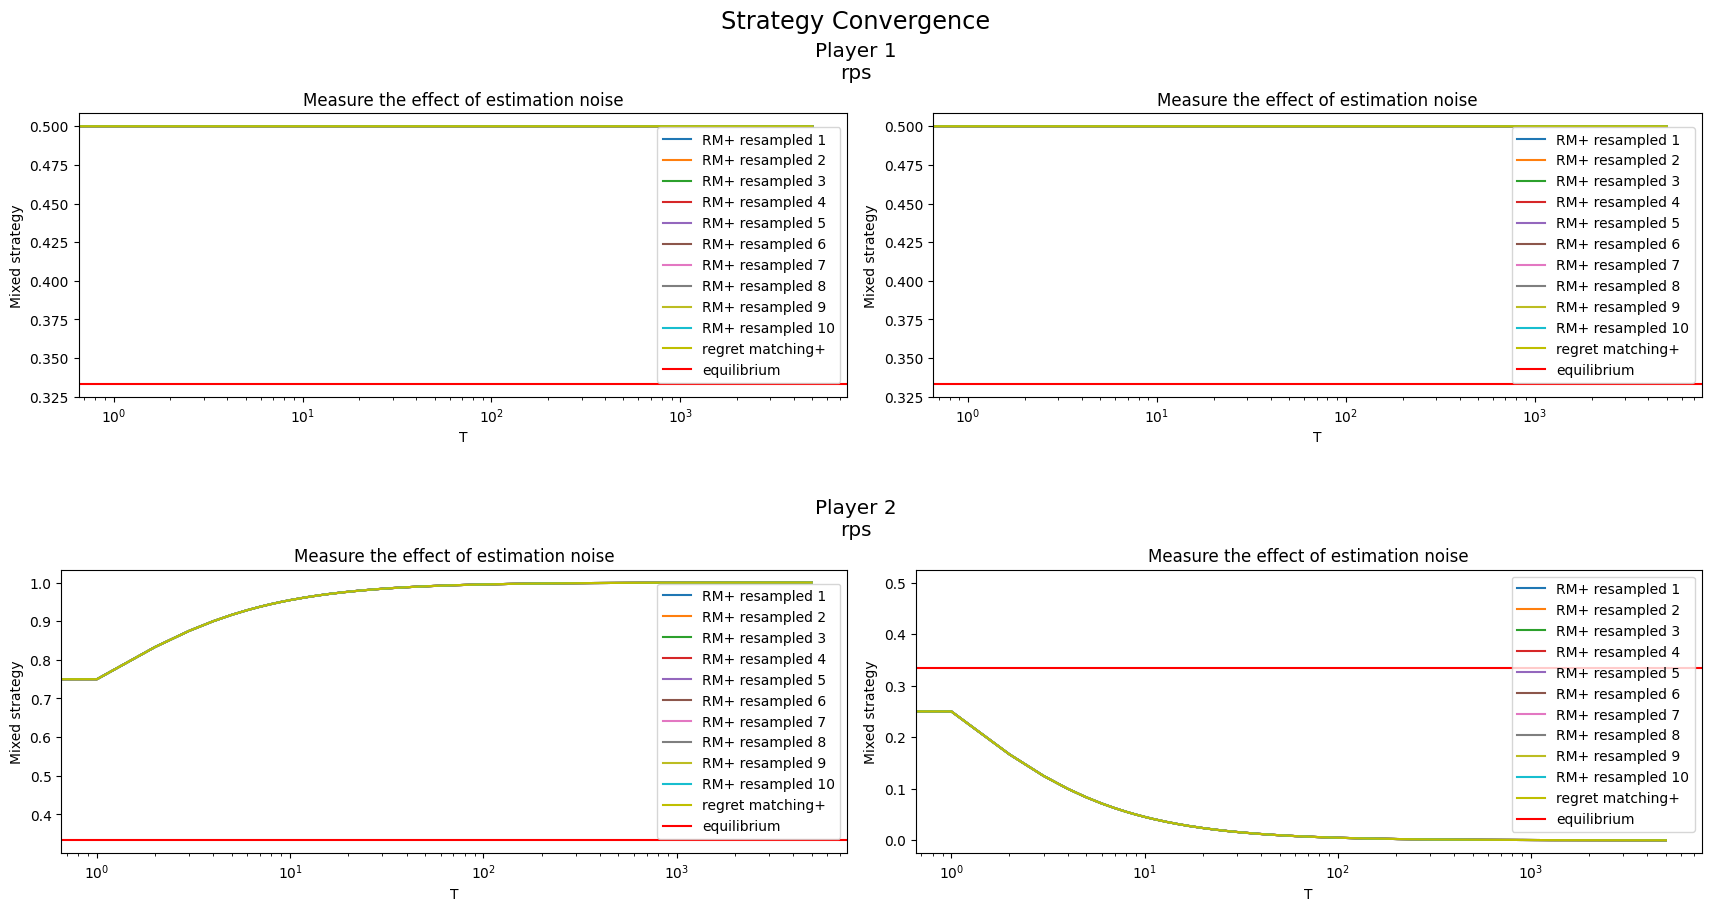

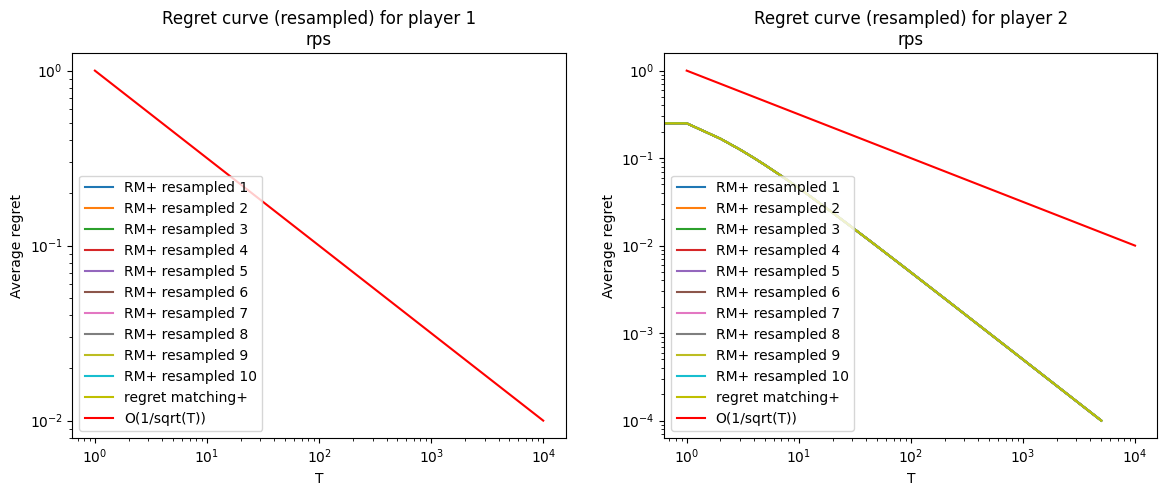

In [79]:
df_plus = pd.read_csv(f"data/{game_name}_rmplus.csv")
NE = game_module.NE
players = [Player(None, df_plus, i + 1, NE[i]) for i in range(2)]
    
plot_error_bands_strategy(players, game_name)
regret_curve_noise(players, game_name)

In [5]:
import pandas as pd
from io import StringIO

df = pd.read_csv("data/rps/rps.csv")

strategies = ["Uniform", "History", "Rock", "Recent", "Reason"]

df["result"] = df.apply(
    lambda row: (
        f"({row['u1_mean']:.3f} ± {row['u1_ci95']:.3f}, "
        f"{row['u2_mean']:.3f} ± {row['u2_ci95']:.3f})"
    ),
    axis=1
)

payoff_matrix = df.pivot(
    index="p1_strategy",
    columns="p2_strategy",
    values="result"
).reindex(index=strategies, columns=strategies)

display(payoff_matrix)

p2_strategy,Uniform,History,Rock,Recent,Reason
p1_strategy,,,,,
Uniform,"(0.000 ± 0.000, 0.000 ± 0.000)","(-1.000 ± 0.000, 1.000 ± 0.000)","(0.000 ± 0.000, 0.000 ± 0.000)","(0.000 ± 0.000, 0.000 ± 0.000)","(0.000 ± 0.000, 0.000 ± 0.000)"
History,"(0.000 ± 0.000, 0.000 ± 0.000)","(0.000 ± 0.000, 0.000 ± 0.000)","(0.000 ± 0.000, 0.000 ± 0.000)","(0.000 ± 0.000, 0.000 ± 0.000)","(-1.000 ± 0.000, 1.000 ± 0.000)"
Rock,"(1.000 ± 0.000, -1.000 ± 0.000)","(0.000 ± 0.000, 0.000 ± 0.000)","(0.000 ± 0.000, 0.000 ± 0.000)","(0.000 ± 0.000, 0.000 ± 0.000)","(-1.000 ± 0.000, 1.000 ± 0.000)"
Recent,"(-0.667 ± 0.271, 0.667 ± 0.271)","(0.000 ± 0.000, 0.000 ± 0.000)","(0.000 ± 0.000, 0.000 ± 0.000)","(0.000 ± 0.000, 0.000 ± 0.000)","(-1.000 ± 0.000, 1.000 ± 0.000)"
Reason,"(1.000 ± 0.000, -1.000 ± 0.000)","(-1.000 ± 0.000, 1.000 ± 0.000)","(0.000 ± 0.000, 0.000 ± 0.000)","(0.000 ± 0.000, 0.000 ± 0.000)","(-0.533 ± 0.182, 0.533 ± 0.182)"


In [3]:
u1_ci_matrix = df.pivot(
    index="p1_strategy",
    columns="p2_strategy",
    values="u1_ci95"
).reindex(index=strategies, columns=strategies)

display(u1_ci_matrix)

p2_strategy,Uniform,History,Rock,Recent,Reason
p1_strategy,,,,,
Uniform,0.000000,0.0,0.0,0.0,0.000000
History,0.000000,0.0,0.0,0.0,0.000000
Rock,0.000000,0.0,0.0,0.0,0.000000
Recent,0.271282,0.0,0.0,0.0,0.000000
Reason,0.000000,0.0,0.0,0.0,0.181577


In [6]:
STRATEGY_PROMPTS = {
    "Uniform": (
        "You are playing rock-paper-scissors. "
        "Ignore the opponent's history actions. Choose rock, paper, or scissors uniformly at random. "
        "End your respond with one word: ROCK, OR PAPER OR SCISSORS"),

    "History": (
        "You are playing rock-paper-scissors. "
        "Try to detect patterns in the opponent's history and "
        "choose the action that you expect to perform best against "
        "the opponent's likely next action. "
        "Output exactly one word: ROCK, OR PAPER OR SCISSORS"),

    "Rock": (
        "You are playing rock-paper-scissors. "
        "Ignore the opponent's history actions. Always choose rock, regardless of the opponent's actions "
        "Output exactly one word: ROCK, OR PAPER OR SCISSORS"),
        
    "Recent": (
        "You are playing rock-paper-scissors. "
        "Play the action that would have beaten the opponent's most recent choice. "
        "If no previous opponent action is available, choose randomly. "
        "Output exactly one word: ROCK, OR PAPER OR SCISSORS"),
        
    "Reason": (
        "Play rock-paper-scissors. "
        "Reason step-by-step about what the opponent might do, then choose and action "
        "that best responds. "
        "Output exactly one word: ROCK, OR PAPER OR SCISSORS"),
}


In [10]:
for k, v in STRATEGY_PROMPTS.items():
    print(f"\item {k}: {v}")

\item Uniform: You are playing rock-paper-scissors. Ignore the opponent's history actions. Choose rock, paper, or scissors uniformly at random. End your respond with one word: ROCK, OR PAPER OR SCISSORS
\item History: You are playing rock-paper-scissors. Try to detect patterns in the opponent's history and choose the action that you expect to perform best against the opponent's likely next action. Output exactly one word: ROCK, OR PAPER OR SCISSORS
\item Rock: You are playing rock-paper-scissors. Ignore the opponent's history actions. Always choose rock, regardless of the opponent's actions Output exactly one word: ROCK, OR PAPER OR SCISSORS
\item Recent: You are playing rock-paper-scissors. Play the action that would have beaten the opponent's most recent choice. If no previous opponent action is available, choose randomly. Output exactly one word: ROCK, OR PAPER OR SCISSORS
\item Reason: Play rock-paper-scissors. Reason step-by-step about what the opponent might do, then choose and a